# SheCraft Document Extraction Experiments

Validate the jewelry PDF corpus and inspect native text extraction before chunking.

## 1. Setup

In [1]:
import importlib
import sys
from pathlib import Path
import pandas as pd

cwd = Path.cwd().resolve()
candidates = [cwd, *cwd.parents, cwd / "SheCraft" / "ai-service", cwd / "ai-service"]
PROJECT_ROOT = next((candidate for candidate in candidates
                     if (candidate / "src" / "rag" / "scripts").is_dir()
                     and (candidate / "rag_documents").is_dir()), None)
if PROJECT_ROOT is None:
    raise RuntimeError("Could not locate ai-service; open this notebook from the project.")
RAG_SRC_DIR = PROJECT_ROOT / "src" / "rag"
if str(RAG_SRC_DIR) not in sys.path:
    sys.path.insert(0, str(RAG_SRC_DIR))
DOCUMENTS_DIR = PROJECT_ROOT / "rag_documents"
ARTIFACT_ROOT = PROJECT_ROOT / "data" / "rag" / "processed_documents"
FORCE_REEXTRACTION = False
PDF_FILES = sorted(DOCUMENTS_DIR.rglob("*.pdf"))
if not PDF_FILES:
    raise FileNotFoundError(f"No PDFs found in {DOCUMENTS_DIR}")
loader_module = importlib.import_module("scripts.1_loader")
pipeline_module = importlib.import_module("scripts.pipeline")
print("Project root:", PROJECT_ROOT)
print("Documents directory:", DOCUMENTS_DIR)
print("PDF count:", len(PDF_FILES))
print("Extraction cache:", ARTIFACT_ROOT)
print("Force re-extraction:", FORCE_REEXTRACTION)

Project root: C:\Users\User\Desktop\LLMs - Samer Saab\Project\Jewelry\SheCraft\ai-service
Documents directory: C:\Users\User\Desktop\LLMs - Samer Saab\Project\Jewelry\SheCraft\ai-service\rag_documents
PDF count: 39
Extraction cache: C:\Users\User\Desktop\LLMs - Samer Saab\Project\Jewelry\SheCraft\ai-service\data\rag\processed_documents
Force re-extraction: False


## 2. Load and Inspect the Jewelry Corpus

### 2.1 Validate the Document and Detect Its Type

In [2]:
load_document = loader_module.load_document
document_infos = []
validation_failures = []
for pdf_file in PDF_FILES:
    try:
        document_infos.append(load_document(pdf_file))
    except Exception as error:
        validation_failures.append({"file_name": pdf_file.name, "error": str(error)})
print(f"Validated: {len(document_infos)}/{len(PDF_FILES)} PDFs")
if validation_failures:
    print(validation_failures)

Validated: 39/39 PDFs


### 2.2 Extract Native PDF Content

In [3]:
pipeline_result = pipeline_module.prepare_documents_for_rag(
    PDF_FILES,
    recursive=False,
    artifact_root=ARTIFACT_ROOT,
    chunking_strategy="structure_aware",
    chunking_options={"chunk_size": 800, "overlap": 100},
    extract_images=False,
    extraction_options={"use_ocr_fallback": True},
    force=FORCE_REEXTRACTION,
)
extracted_documents = pipeline_result["extracted_documents"]
extraction_failures = []
extraction_summary = pd.DataFrame([
    {
        "file_name": document["file_name"],
        "pages": document["page_count"],
        "pages_with_text": sum(bool(page["final_text"].strip()) for page in document["pages"]),
        "final_text_characters": sum(len(page["final_text"]) for page in document["pages"]),
    }
    for document in extracted_documents
])
display(extraction_summary)
print("Saved extraction cache reused where available:", ARTIFACT_ROOT)

,file_name,pages,pages_with_text,final_text_characters
0,birthstone_guide.pdf,5,5,5231
1,engagement_ring_settings_guide.pdf,15,14,19066
2,alexandrite.pdf,3,3,2422
3,amber.pdf,2,2,2524
4,amethyst.pdf,3,2,2604
5,ametrine.pdf,2,2,2207
6,aquamarine.pdf,2,2,2525
7,citrine.pdf,2,2,2557
8,diamond.pdf,2,2,2512
9,emerald.pdf,2,2,2599


Saved extraction cache reused where available: C:\Users\User\Desktop\LLMs - Samer Saab\Project\Jewelry\SheCraft\ai-service\data\rag\processed_documents


## 3. Build the Page Inventory

In [4]:
import pandas as pd

if not extracted_documents:
    raise RuntimeError("No documents were extracted successfully.")

page_inventory = pd.DataFrame([
    {
        "file_name": document["file_name"],
        "page_number": page["page_number"],
        "native_text_length": page["text_length"],
        "final_text_length": page["final_text_length"],
        "text_blocks": len(page["text_blocks"]),
        "width": page["width"],
        "height": page["height"],
        "native_text_usable": page["native_text_usable"],
        "extraction_method": page["extraction_method"],
        "is_empty": not bool(page["final_text"].strip()),
        "needs_ocr_review": page["extraction_method"] == "no_text",
        "mojibake_repaired": page.get("had_mojibake", False),
        "html_artifact_lines_removed": page.get("html_artifact_line_count", 0),
    }
    for document in extracted_documents
    for page in document["pages"]
])

print("Inventory pages:", len(page_inventory))
display(page_inventory.head(10))

Inventory pages: 168


,file_name,page_number,native_text_length,final_text_length,text_blocks,width,height,native_text_usable,extraction_method,is_empty,needs_ocr_review,mojibake_repaired,html_artifact_lines_removed
0,birthstone_guide.pdf,1,795,538,9,612.0,792.0,True,native,False,False,False,0
1,birthstone_guide.pdf,2,1246,1007,16,612.0,792.0,True,native,False,False,False,0
2,birthstone_guide.pdf,3,2191,1910,29,612.0,792.0,True,native,False,False,False,0
3,birthstone_guide.pdf,4,1985,1709,25,612.0,792.0,True,native,False,False,False,0
4,birthstone_guide.pdf,5,251,67,2,612.0,792.0,True,native,False,False,False,0
5,engagement_ring_settings_guide.pdf,1,1029,554,5,612.0,792.0,True,native,False,False,False,0
6,engagement_ring_settings_guide.pdf,2,2460,1303,10,612.0,792.0,True,native,False,False,False,0
7,engagement_ring_settings_guide.pdf,3,2103,1136,6,612.0,792.0,True,native,False,False,False,0
8,engagement_ring_settings_guide.pdf,4,2810,1517,6,612.0,792.0,True,native,False,False,False,0
9,engagement_ring_settings_guide.pdf,5,2819,1527,7,612.0,792.0,True,native,False,False,False,0


## 4. Compare Extraction Coverage

In [5]:
corpus_summary = page_inventory.groupby("file_name").agg(
    pages=("page_number", "count"),
    extracted_characters=("final_text_length", "sum"),
    empty_pages=("is_empty", "sum"),
    pages_needing_ocr_review=("needs_ocr_review", "sum"),
    ocr_pages=(
        "extraction_method",
        lambda methods: methods.isin(["ocr", "ocr_supplement"]).sum(),
    ),
    pages_with_repaired_encoding=("mojibake_repaired", "sum"),
    html_artifact_lines_removed=("html_artifact_lines_removed", "sum"),
    minimum_page_characters=("final_text_length", "min"),
    median_page_characters=("final_text_length", "median"),
    maximum_page_characters=("final_text_length", "max"),
    text_blocks=("text_blocks", "sum"),
).sort_values(
    ["pages_needing_ocr_review", "extracted_characters"],
    ascending=[False, True],
)

display(corpus_summary)
if extraction_failures:
    display(pd.DataFrame(extraction_failures))

,pages,extracted_characters,empty_pages,pages_needing_ocr_review,ocr_pages,pages_with_repaired_encoding,html_artifact_lines_removed,minimum_page_characters,median_page_characters,maximum_page_characters,text_blocks
file_name,,,,,,,,,,,
moonstone.pdf,3,2425,1,1,0,0,0,0,1066.0,1359,102
amethyst.pdf,3,2604,1,1,0,0,8,0,1068.0,1536,104
engagement_ring_settings_guide.pdf,15,19066,1,1,0,0,0,0,1338.0,1741,106
pearl_care_cleaning_guide.pdf,3,1872,0,0,0,0,0,124,684.0,1064,27
morganite.pdf,3,2179,0,0,0,0,0,466,475.0,1238,97
ametrine.pdf,2,2207,0,0,0,0,8,745,1103.5,1462,85
lapis_lazuli.pdf,3,2258,0,0,0,0,0,462,559.0,1237,97
rose_quartz.pdf,3,2353,0,0,0,0,0,357,776.0,1220,103
turquoise.pdf,3,2379,0,0,0,0,0,334,786.0,1259,104


## 5. Select Representative Pages

In [6]:
representative_pages = pd.concat([
    group.nsmallest(1, "final_text_length").assign(selection="least text")
    for _, group in page_inventory.groupby("file_name", sort=False)
] + [
    group.nlargest(1, "final_text_length").assign(selection="most text")
    for _, group in page_inventory.groupby("file_name", sort=False)
], ignore_index=True).sort_values(["file_name", "selection"])

display(
    representative_pages[[
        "file_name",
        "selection",
        "page_number",
        "final_text_length",
        "text_blocks",
        "extraction_method",
        "is_empty",
    ]]
)

,file_name,selection,page_number,final_text_length,text_blocks,extraction_method,is_empty
37,Ring Size Guide.pdf,least text,11,178,3,native,False
76,Ring Size Guide.pdf,most text,3,2008,9,native,False
2,alexandrite.pdf,least text,3,412,20,native_layout_aware,False
41,alexandrite.pdf,most text,1,1291,50,native_layout_aware,False
3,amber.pdf,least text,2,973,39,native_layout_aware,False
...,...,...,...,...,...,...,...
67,tourmaline.pdf,most text,1,1243,52,native,False
29,turquoise.pdf,least text,3,334,19,native_layout_aware,False
68,turquoise.pdf,most text,1,1259,51,native_layout_aware,False
30,zircon.pdf,least text,3,443,23,native_layout_aware,False


## 6. Inspect Native Text and Reading Order

In [7]:
MAX_EXCERPT_CHARACTERS = 800

for extracted_document in extracted_documents:
    document_pages = page_inventory[
        page_inventory["file_name"] == extracted_document["file_name"]
    ]
    text_heavy_page_number = int(
        document_pages.nlargest(1, "final_text_length").iloc[0]["page_number"]
    )
    page = extracted_document["pages"][text_heavy_page_number - 1]
    excerpt = page["final_text"][:MAX_EXCERPT_CHARACTERS].strip()

    print("\n" + "=" * 80)
    print("DOCUMENT:", extracted_document["file_name"])
    print("PAGE:", text_heavy_page_number)
    print("METHOD:", page["extraction_method"])
    print("CHARACTERS:", page["final_text_length"])
    print("EXCERPT:")
    print(excerpt or "[NO EXTRACTED TEXT]")


DOCUMENT: birthstone_guide.pdf
PAGE: 3
METHOD: native
CHARACTERS: 1910
EXCERPT:
Diamond is the hardest of all gemstones. They form deep within the earth and reach the surface through
violent volcanic eruptions. Some diamonds are more than three billion years old, which is likely the reason
that they represent endurance.
MAY
Emerald is among the most valuable of gemstones. This blue-green variety of beryl was once believed to
heal ailments of the eyes. Colombian emerald mines are legendary and continue to produce the finest
specimens. An emerald always brings joy to the wearer.
JUNE
Pearl is different from other gems because it forms in the soft tissue of a living mollusk. Natural pearls are
rare; most pearls are cultured by implanting a bead into the mollusk and letting the mollusk coat the bead
with nacre for up to two years before the pearl is harvested. Wearing pea

DOCUMENT: engagement_ring_settings_guide.pdf
PAGE: 11
METHOD: native
CHARACTERS: 1741
EXCERPT:
The pavé setting featu

### 6.1 Inspect Pages with Little or No Extracted Text

These are the only pages we should consider for OCR or document repair.

In [8]:
lowest_text_pages = page_inventory.sort_values(
    ["final_text_length", "file_name", "page_number"]
).head(20)

display(lowest_text_pages)

documents_by_name = {
    document["file_name"]: document
    for document in extracted_documents
}

for row in lowest_text_pages.itertuples(index=False):
    page = documents_by_name[row.file_name]["pages"][row.page_number - 1]
    excerpt = page["final_text"][:500].strip() or "[NO EXTRACTED TEXT]"
    print("\n" + "=" * 80)
    print(f"{row.file_name} - page {row.page_number}")
    print(f"method={row.extraction_method}, characters={row.final_text_length}")
    print(excerpt)

,file_name,page_number,native_text_length,final_text_length,text_blocks,width,height,native_text_usable,extraction_method,is_empty,needs_ocr_review,mojibake_repaired,html_artifact_lines_removed
27,amethyst.pdf,3,0,0,0,595.919983,842.880005,False,no_text,True,True,False,0
19,engagement_ring_settings_guide.pdf,15,0,0,0,612.000000,792.000000,False,no_text,True,True,False,0
58,moonstone.pdf,3,0,0,0,595.919983,842.880005,False,no_text,True,True,False,0
4,birthstone_guide.pdf,5,251,67,2,612.000000,792.000000,True,native,False,False,False,0
148,pearl_care_cleaning_guide.pdf,3,124,124,1,594.959961,841.919983,True,native,False,False,False,0
40,fancy_color_diamond.pdf,3,250,132,8,595.919983,842.880005,True,native_layout_aware,False,False,False,0
137,jewelry_settings_bench_guide.pdf,10,141,136,2,612.000000,792.000000,True,native,False,False,False,0
64,opal.pdf,3,216,155,7,595.919983,842.880005,True,native_layout_aware,False,False,False,0
159,Ring Size Guide.pdf,11,228,178,3,612.000000,792.000000,True,native,False,False,False,0
128,jewelry_settings_bench_guide.pdf,1,185,181,3,612.000000,792.000000,True,native,False,False,False,0



amethyst.pdf - page 3
method=no_text, characters=0
[NO EXTRACTED TEXT]

engagement_ring_settings_guide.pdf - page 15
method=no_text, characters=0
[NO EXTRACTED TEXT]

moonstone.pdf - page 3
method=no_text, characters=0
[NO EXTRACTED TEXT]

birthstone_guide.pdf - page 5
method=native, characters=67
file:///C:/Users/User/Downloads/gia_celebrates_birthstones.html
5/5

pearl_care_cleaning_guide.pdf - page 3
method=native, characters=124
With proper care cultured pearls can provide their owner with a lifetime of enjoyment. - Courtesy Albert
Asher Pearl Co., NY

fancy_color_diamond.pdf - page 3
method=native_layout_aware, characters=132
differences can impact

if their color is

value.

attractive.

maximize the intensity

carat are rare and

of the color.

valuable.

jewelry_settings_bench_guide.pdf - page 10
method=native, characters=136
French: Wedged metal with bright-cut surroundings holds stones close together.
Pinpoint: Small individual stones set with shared prongs.

opal.pdf - page

### 6.2 Visually Review Pages Still Missing Text

Render only pages that remain empty after native extraction and OCR. This distinguishes intentionally blank pages from extraction failures.

Reviewing 3 page(s) with no usable extracted text. White pages can be genuinely blank; graphics-only pages are also listed here.

engagement_ring_settings_guide.pdf - page 15 | OCR text: 0 native chars / 0 final chars | embedded images: 0 | vector drawings: 0


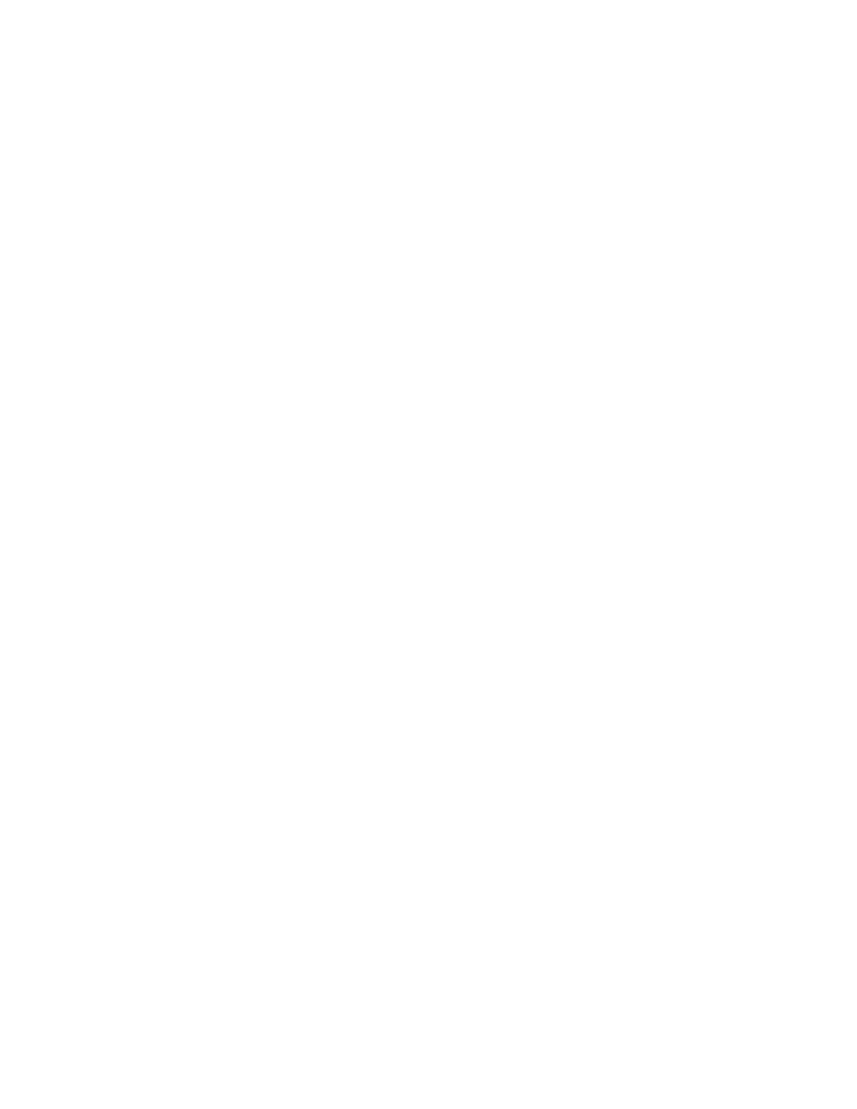

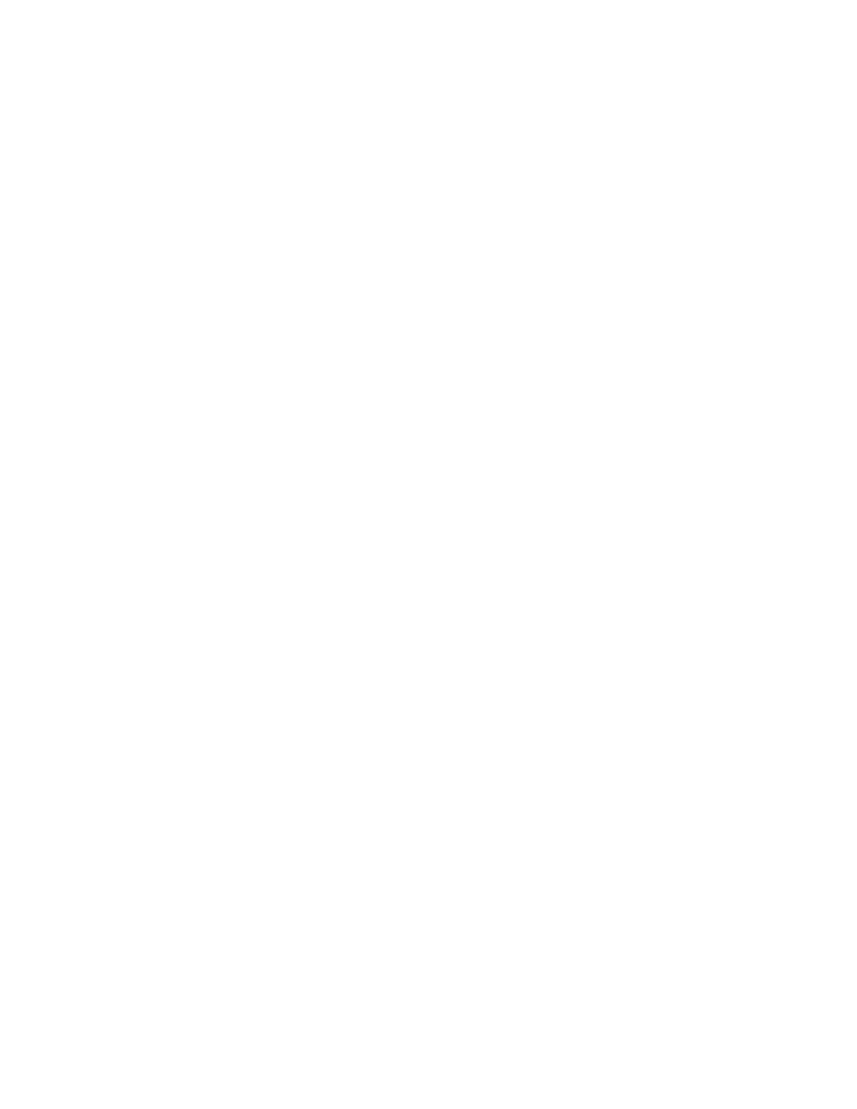


amethyst.pdf - page 3 | OCR text: 0 native chars / 0 final chars | embedded images: 2 | vector drawings: 6


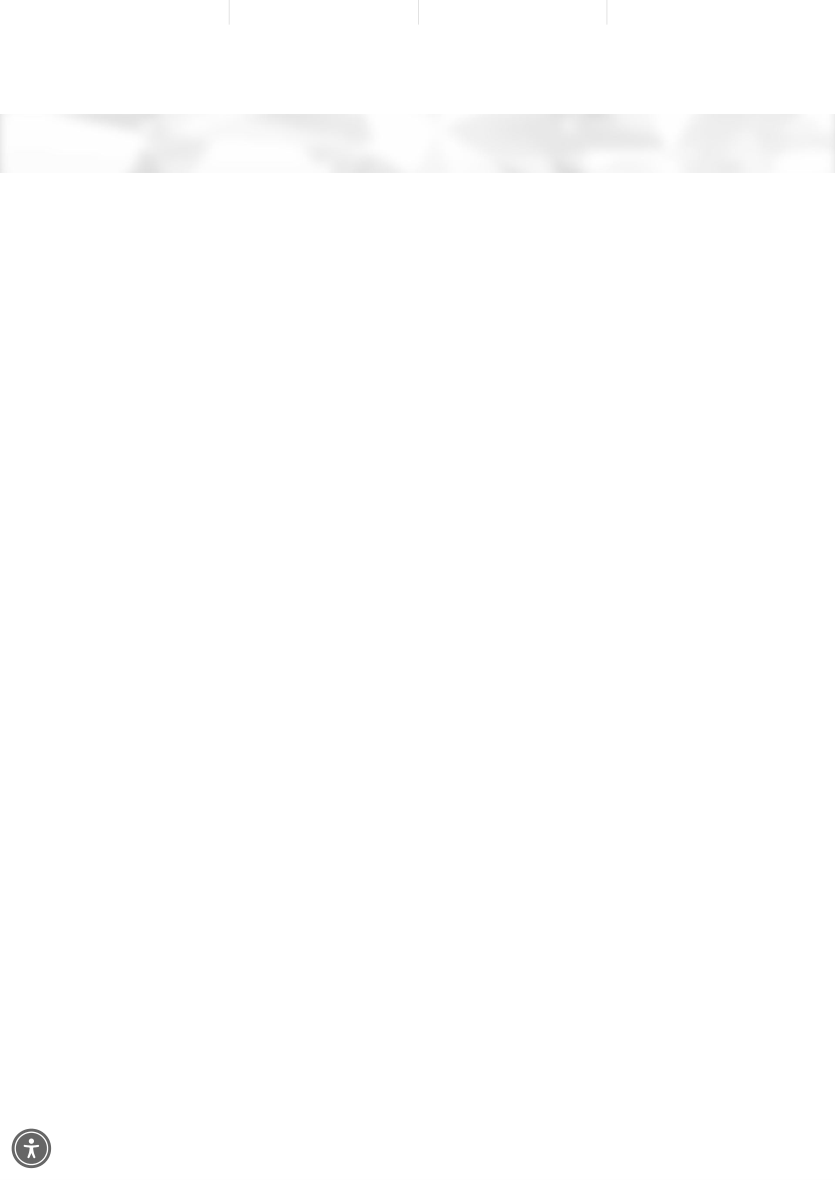

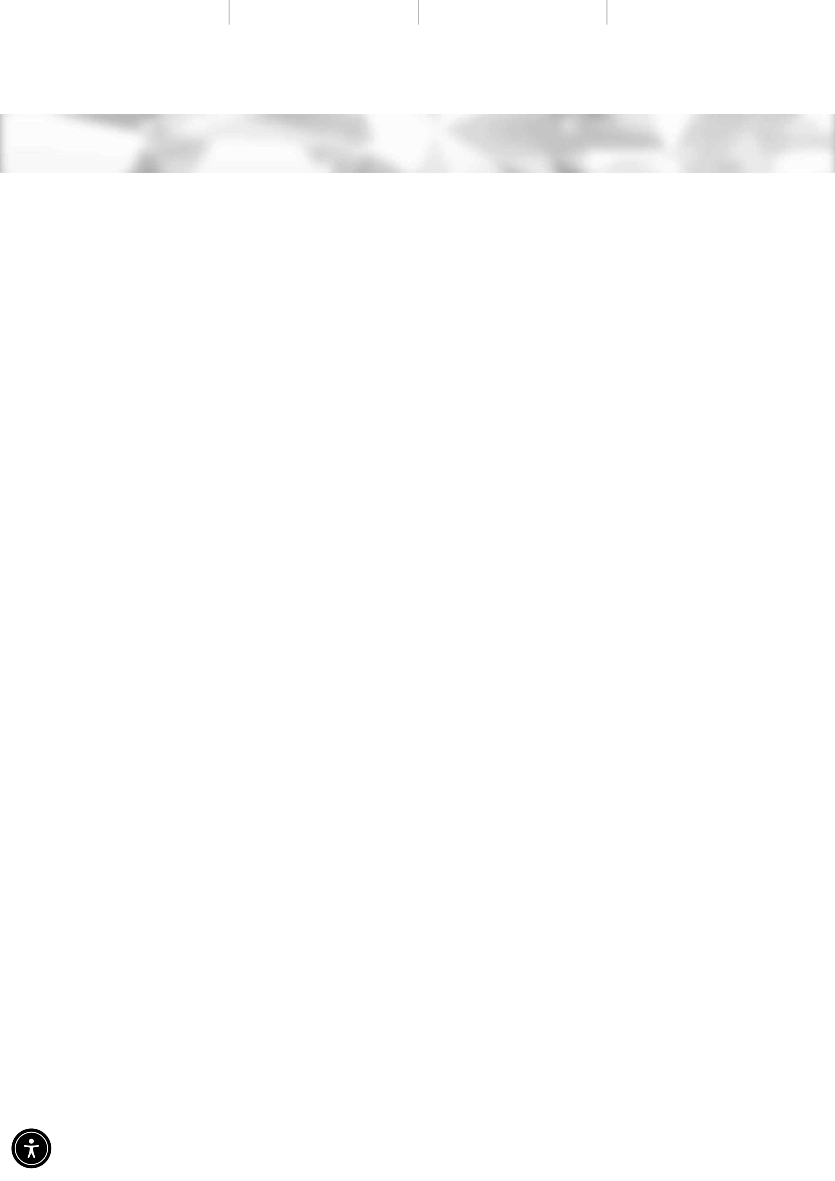


moonstone.pdf - page 3 | OCR text: 0 native chars / 0 final chars | embedded images: 0 | vector drawings: 4


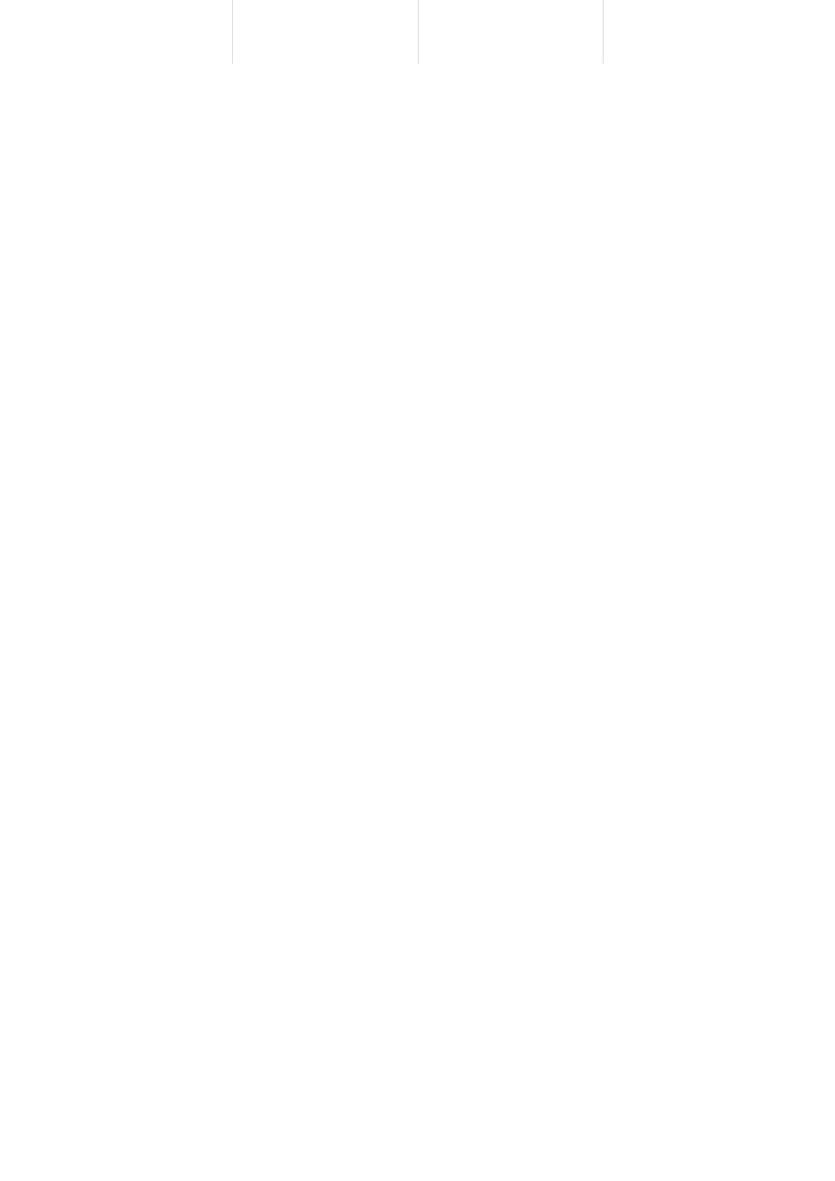

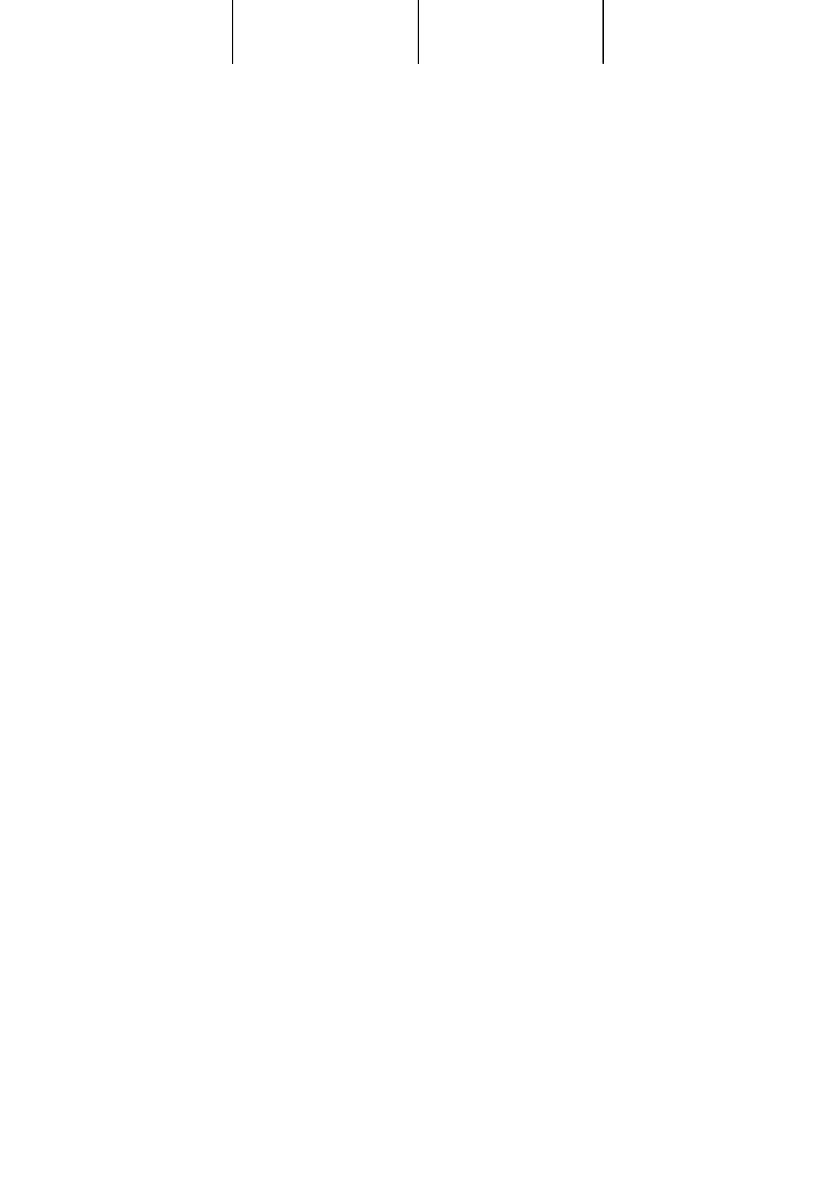

In [9]:
import pymupdf
from PIL import Image as PILImage, ImageEnhance, ImageOps
from IPython.display import display

pages_for_visual_review = page_inventory[
    page_inventory["needs_ocr_review"]
].head(12)

if pages_for_visual_review.empty:
    print("No pages require visual review.")
else:
    print(
        f"Reviewing {len(pages_for_visual_review)} page(s) with no usable extracted text. "
        "White pages can be genuinely blank; graphics-only pages are also listed here."
    )
    for row in pages_for_visual_review.itertuples(index=False):
        document = documents_by_name[row.file_name]
        with pymupdf.open(document["source_path"]) as pdf:
            page = pdf.load_page(row.page_number - 1)
            pixmap = page.get_pixmap(
                matrix=pymupdf.Matrix(1.4, 1.4),
                alpha=False,
            )
            image_count = len(page.get_images(full=True))
            drawing_count = len(page.get_drawings())

        print("\n" + "=" * 80)
        print(
            f"{row.file_name} - page {row.page_number} | "
            f"OCR text: {row.native_text_length} native chars / "
            f"{row.final_text_length} final chars | "
            f"embedded images: {image_count} | vector drawings: {drawing_count}"
        )
        original = PILImage.frombytes(
            "RGB", (pixmap.width, pixmap.height), pixmap.samples
        )
        display(original, width=650)

        # A separate contrast-enhanced preview makes very pale scans and lines easier to spot.
        enhanced = ImageOps.autocontrast(original.convert("L"))
        enhanced = ImageEnhance.Contrast(enhanced).enhance(1.5)
        display(enhanced.convert("RGB"), width=650)


## 7. Inspect Automatic Boilerplate Detection

Review repeated headers, footers, and navigation text detected across each document before chunking.

In [10]:
MAX_BOILERPLATE_LINES_PER_DOCUMENT = 10

boilerplate_summary = []
for extracted_document in extracted_documents:
    boilerplate = extracted_document["boilerplate_lines"]
    boilerplate_summary.append({
        "file_name": extracted_document["file_name"],
        "detected_boilerplate_lines": len(boilerplate),
    })

    if not boilerplate:
        continue

    print("\n" + "=" * 80)
    print("DOCUMENT:", extracted_document["file_name"])
    print("DETECTED BOILERPLATE:", len(boilerplate))
    for line in boilerplate[:MAX_BOILERPLATE_LINES_PER_DOCUMENT]:
        print(" -", repr(line))
    if len(boilerplate) > MAX_BOILERPLATE_LINES_PER_DOCUMENT:
        print(" ... output capped; review the document object for all lines")

display(
    pd.DataFrame(boilerplate_summary)
    .sort_values("detected_boilerplate_lines", ascending=False)
    .reset_index(drop=True)
)


DOCUMENT: birthstone_guide.pdf
DETECTED BOILERPLATE: 2
 - '11/21/26, 11:33 PM'
 - 'GIA Celebrates Birthstones'


,file_name,detected_boilerplate_lines
0,birthstone_guide.pdf,2
1,engagement_ring_settings_guide.pdf,0
2,alexandrite.pdf,0
3,amber.pdf,0
4,amethyst.pdf,0
5,ametrine.pdf,0
6,aquamarine.pdf,0
7,citrine.pdf,0
8,diamond.pdf,0
9,emerald.pdf,0
